C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(


=== Các luật kết hợp tìm được (Apriori) ===
['ALARM CLOCK BAKELIKE GREEN'] ==> ['ALARM CLOCK BAKELIKE RED'] | Sup: 0.0302, Conf: 0.6427
['ALARM CLOCK BAKELIKE RED'] ==> ['ALARM CLOCK BAKELIKE GREEN'] | Sup: 0.0302, Conf: 0.6054
['GREEN REGENCY TEACUP AND SAUCER'] ==> ['PINK REGENCY TEACUP AND SAUCER'] | Sup: 0.0309, Conf: 0.6178
['PINK REGENCY TEACUP AND SAUCER'] ==> ['GREEN REGENCY TEACUP AND SAUCER'] | Sup: 0.0309, Conf: 0.8208
['GREEN REGENCY TEACUP AND SAUCER'] ==> ['ROSES REGENCY TEACUP AND SAUCER'] | Sup: 0.0376, Conf: 0.7505
['ROSES REGENCY TEACUP AND SAUCER'] ==> ['GREEN REGENCY TEACUP AND SAUCER'] | Sup: 0.0376, Conf: 0.7325
['JUMBO  BAG BAROQUE BLACK WHITE'] ==> ['JUMBO BAG RED RETROSPOT'] | Sup: 0.0305, Conf: 0.6264
['JUMBO BAG PINK POLKADOT'] ==> ['JUMBO BAG RED RETROSPOT'] | Sup: 0.0421, Conf: 0.6773
['JUMBO SHOPPER VINTAGE RED PAISLEY'] ==> ['JUMBO BAG RED RETROSPOT'] | Sup: 0.0352, Conf: 0.5799
['JUMBO STORAGE BAG SUKI'] ==> ['JUMBO BAG RED RETROSPOT'] | Sup: 0.0374, Con

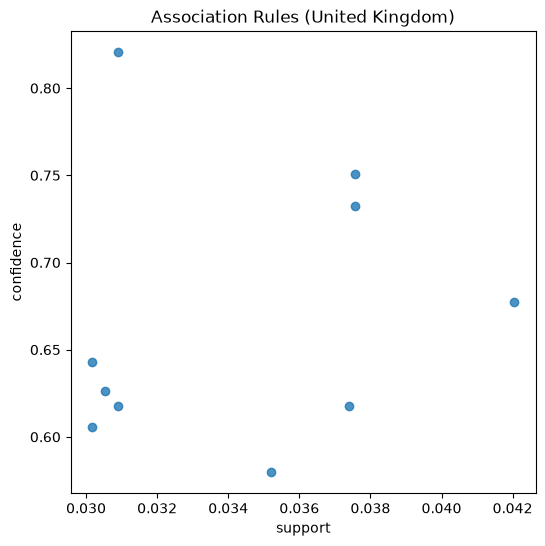

C:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\mlxtend\frequent_patterns\fpcommon.py:175: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(



Số lượng luật tìm được bằng Apriori: 10
Số lượng luật tìm được bằng FP-Growth: 10


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

# 1. Đọc dữ liệu từ file Excel
df_retail = pd.read_excel('Online Retail.xlsx', engine='openpyxl')

# 2. Tiền xử lý dữ liệu: xóa khoảng trắng thừa ở tên sản phẩm, xóa dòng rỗng ở InvoiceNo
df_retail['Description'] = df_retail['Description'].str.strip()
df_retail.dropna(subset=['InvoiceNo'], inplace=True)
df_retail['InvoiceNo'] = df_retail['InvoiceNo'].astype('str')

# 3. Loại bỏ các hóa đơn tín dụng (chứa ký tự 'C')
df_retail = df_retail[~df_retail['InvoiceNo'].str.contains('C', na=False)]

# 4 & 5. Lọc dữ liệu 'United Kingdom' và gom nhóm số lượng theo InvoiceNo và Description
basket = (
    df_retail[df_retail['Country'] == 'United Kingdom']
    .groupby(['InvoiceNo', 'Description'])['Quantity']
    .sum().unstack().reset_index().fillna(0)
    .set_index('InvoiceNo')
)

# 6 & 7. Chuyển dữ liệu sang dạng One-Hot Encoding (0 và 1)
def encode_units(x):
    return 1 if x >= 1 else 0

# Sử dụng map thay cho applymap để tương thích với Pandas mới
basket_sets = basket.map(encode_units)

# 8. Xóa cột POSTAGE nếu có trong dữ liệu
if 'POSTAGE' in basket_sets.columns:
    basket_sets.drop('POSTAGE', inplace=True, axis=1)

# 9. Tìm tập phổ biến bằng thuật toán Apriori với min_sup = 3%
frequent_itemsets_apriori = apriori(basket_sets, min_support=0.03, use_colnames=True)

# 10. Tạo luật kết hợp với min_conf = 50% (0.50)
rules_apriori = association_rules(frequent_itemsets_apriori, metric="confidence", min_threshold=0.50)

print("=== Các luật kết hợp tìm được (Apriori) ===")
for idx, row in rules_apriori.iterrows():
    print(f"{list(row['antecedents'])} ==> {list(row['consequents'])} | Sup: {row['support']:.4f}, Conf: {row['confidence']:.4f}")

# 11. Vẽ đồ thị scatter plot biểu diễn Support và Confidence
plt.figure(figsize=(6, 6))
plt.title('Association Rules (United Kingdom)')
plt.xlabel('Support')
plt.ylabel('Confidence')
sns.regplot(x=rules_apriori['support'], y=rules_apriori['confidence'], fit_reg=False)
plt.show()

# 12. Tìm tập phổ biến & luật kết hợp bằng thuật toán FP-Growth
frequent_itemsets_fp = fpgrowth(basket_sets, min_support=0.03, use_colnames=True)
rules_fp = association_rules(frequent_itemsets_fp, metric="confidence", min_threshold=0.50)

print(f"\nSố lượng luật tìm được bằng Apriori: {len(rules_apriori)}")
print(f"Số lượng luật tìm được bằng FP-Growth: {len(rules_fp)}")